## Titanic Survival Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
print("Titanic Analysis Started!")

Titanic Analysis Started!


In [2]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"

df = pd.read_csv(url)

print("Dataset Loaded!")

Dataset Loaded!


In [3]:
print(df.head())
print("\nShape:", df.shape)
df.info()

   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  

Shape: (891, 15)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 n

In [4]:
data = df.copy()

data = data.drop_duplicates()

data["age"] = data["age"].fillna(data["age"].median())
data["fare"] = data["fare"].fillna(data["fare"].median())
data["embarked"] = data["embarked"].fillna(
    data["embarked"].mode()[0]
)

print("Cleaning Completed!")
print(data.isnull().sum())

Cleaning Completed!
survived         0
pclass           0
sex              0
age              0
sibsp            0
parch            0
fare             0
embarked         0
class            0
who              0
adult_male       0
deck           582
embark_town      2
alive            0
alone            0
dtype: int64


In [5]:
print("Survival Count:")
print(data["survived"].value_counts())

print("\nSurvival Percentage:")
print(data["survived"].value_counts(normalize=True) * 100)

Survival Count:
survived
0    461
1    323
Name: count, dtype: int64

Survival Percentage:
survived
0    58.80102
1    41.19898
Name: proportion, dtype: float64


In [6]:
print("Gender Survival:")
print(data.groupby("sex")["survived"].mean() * 100)

print("\nClass Survival:")
print(data.groupby("pclass")["survived"].mean() * 100)

Gender Survival:
sex
female    74.061433
male      21.588595
Name: survived, dtype: float64

Class Survival:
pclass
1    63.084112
2    50.909091
3    25.679012
Name: survived, dtype: float64


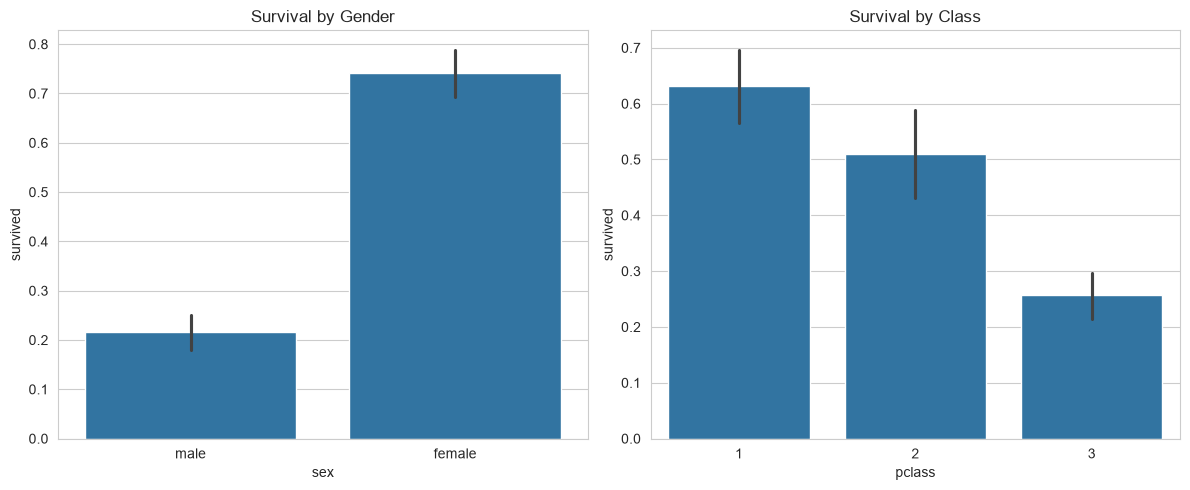

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(data=data, x="sex", y="survived", ax=ax[0])
ax[0].set_title("Survival by Gender")

sns.barplot(data=data, x="pclass", y="survived", ax=ax[1])
ax[1].set_title("Survival by Class")

plt.tight_layout()
plt.show()

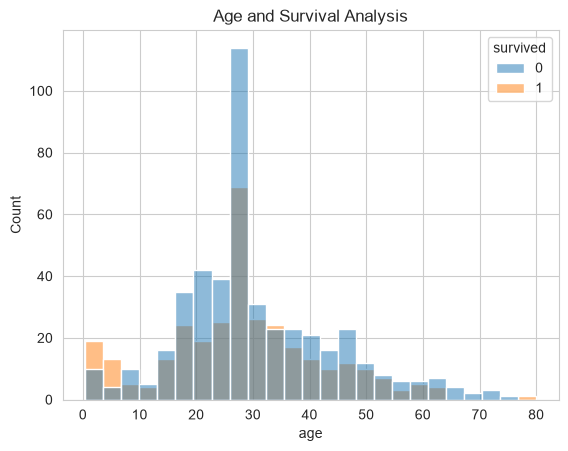

Total Passengers: 784
Total Survivors: 323
Titanic Analysis Completed!


In [8]:
sns.histplot(data=data, x="age", hue="survived", bins=25)

plt.title("Age and Survival Analysis")
plt.show()

print("Total Passengers:", len(data))
print("Total Survivors:", data["survived"].sum())
print("Titanic Analysis Completed!")

In [9]:
data.to_csv("Titanic_Survival_Analysis.csv", index=False)

print("Titanic CSV File Saved Successfully!")

Titanic CSV File Saved Successfully!
